# Dummy and logistic-regression baseline

This notebook gives a shorter walkthrough of the two simplest metadata models before considering more flexible alternatives.

Does learning from age, sex and site improve predictions over assigning everyone the training data's malignant-image rate?

[02_patient_splitting_d1.ipynb](02_patient_splitting_d1.ipynb) created the patient folds used here. This notebook introduces the dummy and standard logistic models on those folds. The companion [03_metadata_model_d1.ipynb](03_metadata_model_d1.ipynb) uses the same references in a broader five-model comparison.

The saved logistic model reaches AP 0.0418, compared with 0.0184 for the dummy. Both models leave every image unflagged at a probability cutoff of 0.50. The reserved test set is not used.


## Context and methods

The prevalence dummy predicts the malignant-image rate in each training fold. Logistic regression learns associations between malignancy and age, sex and anatomical site. The three fields are represented as categories; the model learns from scratch and uses no image pixels.

Every score is out-of-fold (OOF). We fit on four patient folds and predict the fifth, repeating until every image has a prediction from a model that did not train on that patient's images. Category encoding is learned inside each training fit. The diagnosis and benign/malignant labels would reveal the answer, so they are excluded along with identifiers and fold numbers.

Average precision (AP) is our main measure because malignant images are rare. It rewards putting them near the top of a risk ranking; it is not the fraction of images classified correctly. ROC-AUC describes how often a malignant image receives a higher score than a benign image. A value of 0.5 indicates chance-level ranking.

We first show decisions at 0.50, then choose an exploratory logistic cutoff using the same held-out predictions. The latter illustrates a trade-off and can overstate how well the selected cutoff will work on new patients. Notebook 04b later chooses cutoffs using training patients only.


## Data

### 1. Load and check the patient folds

The counts below describe the same 6,864 development images used in notebook 03. We check that each patient belongs to one fold before training. The reserved test data is not loaded.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook from the project root or notebooks directory.")

DATA_PATH = PROJECT_ROOT / "data" / "subset" / "processed" / "train_folds.csv"
FEATURE_COLUMNS = [
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
]
MODEL_LABELS = {
    "dummy": "Prevalence dummy",
    "logistic": "Logistic regression",
}
COLORS = {
    "dummy": "#94A3B8",
    "logistic": "#2563EB",
}


def build_logistic_metadata_pipeline(feature_columns=FEATURE_COLUMNS):
    '''Build the logistic pipeline directly in this standalone notebook.'''
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                list(feature_columns),
            )
        ],
        remainder="drop",
    )
    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    solver="liblinear",
                    max_iter=1_000,
                    random_state=42,
                ),
            ),
        ]
    )


def generate_oof_probabilities(
    frame,
    estimator,
    feature_columns=FEATURE_COLUMNS,
    *,
    target_col="target",
    fold_col="fold",
    group_col="patient_id",
    prediction_name="probability",
):
    '''Create validation probabilities while keeping each patient in one fold.'''
    features = list(feature_columns)
    if frame.groupby(group_col)[fold_col].nunique().gt(1).any():
        raise ValueError("At least one patient appears in multiple folds.")

    probabilities = np.full(len(frame), np.nan, dtype=float)
    for fold in sorted(frame[fold_col].unique()):
        validation_mask = frame[fold_col].eq(fold).to_numpy()
        training_mask = ~validation_mask
        fold_estimator = clone(estimator)
        fold_estimator.fit(
            frame.loc[training_mask, features],
            frame.loc[training_mask, target_col],
        )
        positive_class_position = list(fold_estimator.classes_).index(1)
        probabilities[validation_mask] = fold_estimator.predict_proba(
            frame.loc[validation_mask, features]
        )[:, positive_class_position]

    if np.isnan(probabilities).any():
        raise RuntimeError("At least one image did not receive an OOF prediction.")
    return pd.Series(probabilities, index=frame.index, name=prediction_name)


def binary_probability_metrics(targets, probabilities):
    '''Calculate the four probability metrics used in this notebook.'''
    return {
        "roc_auc": float(roc_auc_score(targets, probabilities)),
        "average_precision": float(average_precision_score(targets, probabilities)),
        "log_loss": float(log_loss(targets, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(targets, probabilities)),
    }

train = pd.read_csv(DATA_PATH, dtype={"age_approx": "string"})
required_columns = {
    "image_name",
    "patient_id",
    "target",
    "fold",
    *FEATURE_COLUMNS,
}
missing_columns = required_columns - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

assert set(train["target"]) == {0, 1}, "The target must contain both binary classes."
assert set(train["fold"]) == {0, 1, 2, 3, 4}, "Expected five folds labelled 0-4."
assert train[FEATURE_COLUMNS].notna().all().all(), "Metadata contains missing values."
assert train.groupby("patient_id")["fold"].nunique().eq(1).all(), (
    "At least one patient appears in multiple folds."
)

print(f"Source: {DATA_PATH}")
print(f"Images: {len(train):,}")
print(f"Patients: {train['patient_id'].nunique():,}")
print(f"Malignant images: {int(train['target'].sum()):,} ({train['target'].mean():.2%})")
print(f"Features: {FEATURE_COLUMNS}")


Source: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\train_folds.csv
Images: 6,864
Patients: 422
Malignant images: 128 (1.86%)
Features: ['sex', 'age_approx', 'anatom_site_general_challenge']


## Results

### 2. Generate held-out probabilities

Both methods train and predict on exactly the same patient splits. The dummy gives one constant probability within each fold. Its five printed probabilities differ slightly because each training fold has a slightly different malignant-image rate.


In [2]:
estimators = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": build_logistic_metadata_pipeline(),
}

oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
for model_name, estimator in estimators.items():
    probability_column = f"{model_name}_probability"
    oof_predictions[probability_column] = generate_oof_probabilities(
        train,
        estimator,
        FEATURE_COLUMNS,
        prediction_name=probability_column,
    )

probability_columns = [f"{model_name}_probability" for model_name in estimators]
assert oof_predictions[probability_columns].notna().all().all()
assert oof_predictions[probability_columns].apply(
    lambda values: values.between(0, 1).all()
).all()

print(f"Created OOF probabilities for {len(oof_predictions):,} images.")
print("Distinct dummy probabilities:")
print(np.sort(oof_predictions["dummy_probability"].unique()))


Created OOF probabilities for 6,864 images.
Distinct dummy probabilities:
[0.01856571 0.01857247 0.01860295 0.01874772 0.01875114]


### 3. Compare ranking scores

Read the pooled OOF scores as the result across all held-out images. The mean fold ROC-AUC averages the five separate fold scores. They need not be identical. The following table also checks that the dummy has exactly 0.5 ROC-AUC within each fold, as expected for a constant score.


In [3]:
metric_rows = []
fold_metric_rows = []

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall_metrics = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )

    fold_auc_values = []
    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_auc = roc_auc_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_ap = average_precision_score(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        fold_auc_values.append(fold_auc)
        fold_metric_rows.append(
            {
                "Model": MODEL_LABELS[model_name],
                "Fold": int(fold),
                "ROC-AUC": fold_auc,
                "Average precision": fold_ap,
            }
        )

    metric_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Pooled OOF ROC-AUC": overall_metrics["roc_auc"],
            "Mean fold ROC-AUC": np.mean(fold_auc_values),
            "Average precision": overall_metrics["average_precision"],
        }
    )

metrics = pd.DataFrame(metric_rows).set_index("Model")
fold_metrics = pd.DataFrame(fold_metric_rows)

metrics.round(4)


,Pooled OOF ROC-AUC,Mean fold ROC-AUC,Average precision
Model,,,
Prevalence dummy,0.4952,0.500,0.0184
Logistic regression,0.5945,0.593,0.0418


In [4]:
dummy_fold_check = fold_metrics.query("Model == 'Prevalence dummy'").copy()
dummy_fold_check["Validation prevalence"] = (
    oof_predictions.groupby("fold")["target"].mean().to_numpy()
)
dummy_fold_check[["Fold", "ROC-AUC", "Average precision", "Validation prevalence"]].round(6)


,Fold,ROC-AUC,Average precision,Validation prevalence
0,0,0.5,0.018248,0.018248
1,1,0.5,0.018950,0.018950
2,2,0.5,0.018827,0.018827
3,3,0.5,0.018235,0.018235
4,4,0.5,0.018978,0.018978


### 4. Read the ROC and precision-recall curves

These curves show what happens as the cutoff changes. Blue represents logistic regression and grey represents the dummy.

In the left panel, the horizontal axis is the fraction of benign images wrongly flagged and the vertical axis is the fraction of malignant images found (recall). A curve closer to the upper-left corner is preferable. The dark dashed diagonal is chance-level ranking.

In the right panel, the horizontal axis is recall and the vertical axis is precision, the fraction of flagged images that are malignant. A higher curve at the same recall means fewer false alarms among flagged images. The dashed horizontal line is the 1.86% malignant-image rate. The high endpoint at recall zero does not mean the model can find every malignant case perfectly.

The curves let us see ranking performance across cutoffs. They also explain why logistic regression can improve on the dummy while still producing low precision.


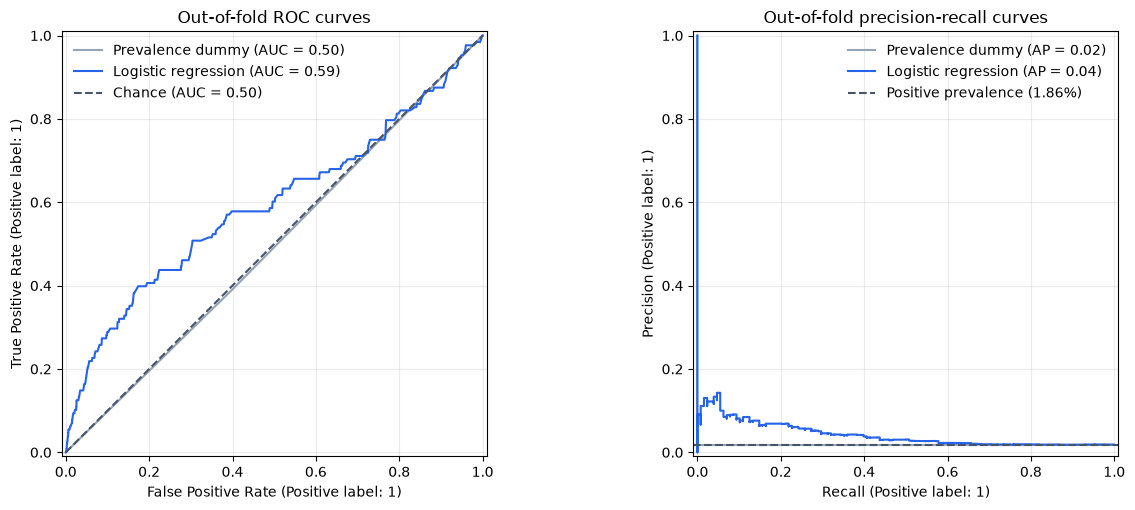

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[0],
    )
    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[1],
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#475569", label="Chance (AUC = 0.50)")
axes[0].set_title("Out-of-fold ROC curves")
axes[0].legend(frameon=False)

positive_prevalence = train["target"].mean()
axes[1].axhline(
    positive_prevalence,
    linestyle="--",
    color="#475569",
    label=f"Positive prevalence ({positive_prevalence:.2%})",
)
axes[1].set_title("Out-of-fold precision-recall curves")
axes[1].legend(frameon=False)

for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
plt.show()


### 5. Choose an exploratory cutoff

A cutoff turns a probability into a flag. At 0.50, both models leave every image unflagged. Their scores are mostly small because malignant images are rare.

For the logistic model, we also try its distinct probabilities as candidate cutoffs and choose the one with the highest balanced accuracy. This averages recall and specificity, the fraction of benign images left unflagged, giving both classes equal weight. The dummy stays at 0.50 because its constant score provides no useful within-fold ranking.

The same OOF labels choose and assess the logistic cutoff, so its result is exploratory. It has not been checked on an independent final test.


In [6]:
def select_balanced_accuracy_threshold(y_true, probabilities):
    candidates = np.unique(np.concatenate(([0.0], probabilities, [1.0])))
    scores = np.array(
        [balanced_accuracy_score(y_true, probabilities >= threshold) for threshold in candidates]
    )
    best_indices = np.flatnonzero(np.isclose(scores, scores.max()))
    best_index = best_indices[
        np.argmin(np.abs(candidates[best_indices] - 0.50))
    ]
    return float(candidates[best_index]), float(scores[best_index])


y_true = oof_predictions["target"].to_numpy()
logistic_probabilities = oof_predictions["logistic_probability"].to_numpy()
logistic_threshold, logistic_balanced_accuracy = select_balanced_accuracy_threshold(
    y_true,
    logistic_probabilities,
)

default_threshold_rows = []
for model_name in estimators:
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        probabilities >= 0.50,
        labels=[0, 1],
    ).ravel()
    default_threshold_rows.append(
        {"Model": MODEL_LABELS[model_name], "Threshold": 0.50, "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    )

print("Default 0.50 threshold:")
display(pd.DataFrame(default_threshold_rows).set_index("Model"))
print(f"Selected logistic threshold: {logistic_threshold:.6f}")
print(f"Balanced accuracy at the selected threshold: {logistic_balanced_accuracy:.4f}")


Default 0.50 threshold:


,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6736,0,128,0
Logistic regression,0.5,6736,0,128,0


Selected logistic threshold: 0.027309
Balanced accuracy at the selected threshold: 0.6124


### 6. Read the confusion matrices

Each matrix shows the decisions made at the cutoff printed above it. Rows are the actual class and columns are the predicted class. TN is a benign image left unflagged; FP is a benign image flagged by mistake. FN is a missed malignant image; TP is a malignant image found.

The percentages add to 100% within each row: the top row describes benign images and the bottom row describes malignant images. Compare TP with FN to see how many malignant cases are found or missed, then check FP to see the false-alarm cost. Darker blue represents more images, but each panel has its own colour scale, so compare the printed numbers across models.

This figure makes the cutoff trade-off concrete. The logistic model finds 51 of 128 malignant images (39.8%) and wrongly flags 1,170 of 6,736 benign images (17.4%). Only 4.2% of its flagged images are malignant.


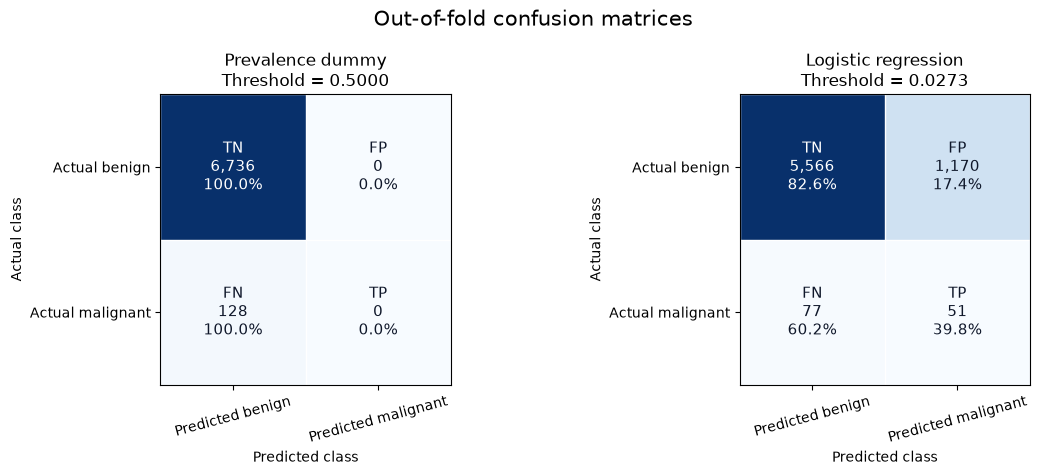

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6736,100.0,0,0.0,128,100.0,0,0.0,0.0
Logistic regression,0.0273,5566,82.6,1170,17.4,77,60.2,51,39.8,4.2


In [7]:
matrix_settings = {
    "dummy": 0.50,
    "logistic": logistic_threshold,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
confusion_rows = []

for axis, model_name in zip(axes, estimators):
    threshold = matrix_settings[model_name]
    probabilities = oof_predictions[f"{model_name}_probability"].to_numpy()
    predicted_labels = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_true, predicted_labels, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()

    row_percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100
    annotations = np.array(
        [
            [
                f"TN\n{tn:,}\n{row_percentages[0, 0]:.1f}%",
                f"FP\n{fp:,}\n{row_percentages[0, 1]:.1f}%",
            ],
            [
                f"FN\n{fn:,}\n{row_percentages[1, 0]:.1f}%",
                f"TP\n{tp:,}\n{row_percentages[1, 1]:.1f}%",
            ],
        ]
    )
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > matrix.max() / 2 else "#0F172A"
            axis.text(
                column,
                row,
                annotations[row, column],
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
            )
    axis.set_xticks([0, 1], labels=["Predicted benign", "Predicted malignant"])
    axis.set_yticks([0, 1], labels=["Actual benign", "Actual malignant"])
    axis.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    axis.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    axis.grid(which="minor", color="white", linestyle="-", linewidth=1)
    axis.tick_params(which="minor", bottom=False, left=False)
    axis.set_title(f"{MODEL_LABELS[model_name]}\nThreshold = {threshold:.4f}")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=15)
    axis.tick_params(axis="y", rotation=0)

    confusion_rows.append(
        {
            "Model": MODEL_LABELS[model_name],
            "Threshold": threshold,
            "TN": tn,
            "TN % of actual benign": row_percentages[0, 0],
            "FP": fp,
            "FP % of actual benign": row_percentages[0, 1],
            "FN": fn,
            "FN % of actual malignant": row_percentages[1, 0],
            "TP": tp,
            "TP % of actual malignant": row_percentages[1, 1],
            "Precision among predicted malignant (%)": (
                tp / (tp + fp) * 100 if (tp + fp) else 0.0
            ),
        }
    )

fig.suptitle("Out-of-fold confusion matrices", fontsize=15)
fig.tight_layout()
plt.show()

confusion_results = pd.DataFrame(confusion_rows).set_index("Model")
confusion_results.round(
    {
        "Threshold": 4,
        "TN % of actual benign": 1,
        "FP % of actual benign": 1,
        "FN % of actual malignant": 1,
        "TP % of actual malignant": 1,
        "Precision among predicted malignant (%)": 1,
    }
)


## Limitations

This is a short development comparison of two fixed models. It does not establish the best metadata model or provide uncertainty intervals for their difference. The same patient folds have also guided the wider model comparison, so later model choices based on these scores may look optimistic.

The logistic cutoff is selected and assessed using the same OOF labels. Its confusion matrix illustrates a possible trade-off; it cannot establish how well that cutoff will work on new patients. The low malignant-image rate also means a model can make few overall errors while missing many malignant cases.

Age, sex and site do not describe lesion appearance. These results do not establish calibrated risks, causation, clinical safety or performance on the reserved test set. See notebook 04b for the later uncertainty and cutoff checks.


## Summary

Logistic regression improves AP from 0.0184 to 0.0418 and pooled ROC-AUC from 0.4952 to 0.5945. The dummy has exactly 0.5 ROC-AUC within every fold; its pooled value differs slightly because the five training-fold prevalences differ.

Retain the dummy as the no-skill reference and standard logistic regression as a simple comparison. The broader notebook 03 favours the spline as the primary metadata model. The exploratory logistic cutoff finds some malignant images at the cost of many false alarms, so it should not be adopted as a clinical rule.

Next, read the broader comparison in notebook 03, then use notebook 03b to compare the small metadata network. Notebook 04b checks uncertainty and decisions selected from training patients.
